# AI-Powered Room Interior Designer — Live Demo
**ARTI 308 Final Project**

Stable Diffusion v1.5 + LoRA adapter for interior design.

**Before running:** `Runtime` → `Change runtime type` → `T4 GPU` (free) or A100/L4 (Colab Pro).

Total run time on free T4: ~5 min setup, then ~10 sec per image.

## 1. Check GPU

In [1]:
!nvidia-smi

Sun May 31 15:52:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies (~2 min)

## 3. Load Stable Diffusion v1.5 base model (~2 min)

In [ ]:
import torch
from diffusers import StableDiffusionPipeline, DDIMScheduler

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# Load the fp16 weight files only (variant="fp16") to halve download size and VRAM.
pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL,
    dtype=torch.float16,
    variant="fp16",
    safety_checker=None,
    requires_safety_checker=False,
).to("cuda")

pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe.enable_attention_slicing()
print("Base SD v1.5 loaded.")

## 4. Load the Interior Design LoRA

Two options. **Run only one of the two cells below.**

### Option A — Use a LoRA from Civitai (recommended)
1. Go to https://civitai.com → search `interior design` → pick any SD 1.5 LoRA → click **Download**.
2. Upload the `.safetensors` file to Colab (left sidebar → files icon → upload).
3. Set `LORA_PATH` below to its name and run the cell.

### Option B — Skip LoRA (vanilla SD only)
If you can't get a LoRA right now, skip this section. The next cells will still work and show vanilla SD output.

In [4]:
# OPTION A: load a downloaded LoRA file
LORA_PATH = "interior_design.safetensors"  # change to your uploaded file name
LORA_SCALE = 0.8  # strength of the LoRA (0.0–1.0)

import os
if os.path.exists(LORA_PATH):
    pipe.load_lora_weights(".", weight_name=LORA_PATH)
    pipe.fuse_lora(lora_scale=LORA_SCALE)
    print(f"LoRA loaded from {LORA_PATH} at scale {LORA_SCALE}.")
    LORA_LOADED = True
else:
    print(f"No LoRA file found at {LORA_PATH}. Running vanilla SD only.")
    LORA_LOADED = False

No LoRA file found at interior_design.safetensors. Running vanilla SD only.


## 5. Generation function

In [5]:
def generate(prompt, seed=42, steps=30, cfg=7.5):
    generator = torch.Generator("cuda").manual_seed(seed)
    negative = "low quality, blurry, distorted, deformed, watermark, text, cartoon, anime"
    image = pipe(
        prompt=prompt,
        negative_prompt=negative,
        num_inference_steps=steps,
        guidance_scale=cfg,
        generator=generator,
        width=512,
        height=512,
    ).images[0]
    return image

print("Ready.")

Ready.


## 6. Quick test

  0%|          | 0/30 [00:00<?, ?it/s]

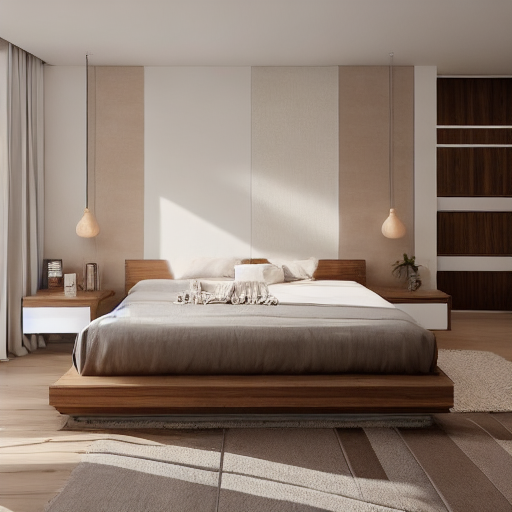

In [6]:
prompt = "modern bedroom with beige tones, soft natural lighting, wooden floor, minimalist furniture, photorealistic"
img = generate(prompt, seed=42)
img

## 7. Side-by-side comparison (vanilla SD vs SD + LoRA)

**Run this only if you loaded a LoRA in Section 4.** It unloads the LoRA, generates with vanilla SD, reloads the LoRA, generates again, and shows both side by side.

In [7]:
import matplotlib.pyplot as plt

test_prompts = [
    "modern bedroom with beige tones, soft lighting, wooden floor",
    "Scandinavian living room, white walls, plants, large window",
    "industrial kitchen with exposed brick and black countertops",
]

if LORA_LOADED:
    # generate WITH LoRA
    with_lora = [generate(p, seed=42) for p in test_prompts]
    # unfuse and generate WITHOUT LoRA
    pipe.unfuse_lora()
    pipe.unload_lora_weights()
    without_lora = [generate(p, seed=42) for p in test_prompts]
    # reload for the rest of the session
    pipe.load_lora_weights(".", weight_name=LORA_PATH)
    pipe.fuse_lora(lora_scale=LORA_SCALE)

    fig, axes = plt.subplots(len(test_prompts), 2, figsize=(10, 5 * len(test_prompts)))
    for i, p in enumerate(test_prompts):
        axes[i, 0].imshow(without_lora[i]); axes[i, 0].set_title("Vanilla SD v1.5"); axes[i, 0].axis("off")
        axes[i, 1].imshow(with_lora[i]); axes[i, 1].set_title("SD v1.5 + LoRA (Ours)"); axes[i, 1].axis("off")
        fig.text(0.5, 1 - (i + 0.95) / len(test_prompts), p, ha="center", fontsize=10, style="italic")
    plt.tight_layout()
    plt.savefig("comparison.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("Saved comparison.png — download from the left sidebar for your slides.")
else:
    print("No LoRA loaded — skipping comparison.")

No LoRA loaded — skipping comparison.


## 8. Live demo UI (Gradio)

Run this cell during the presentation. It opens a web UI where the doctor can type any prompt and get an image.

In [8]:
import gradio as gr

def demo_fn(prompt, seed, steps, cfg):
    return generate(prompt, seed=int(seed), steps=int(steps), cfg=float(cfg))

with gr.Blocks(title="AI Interior Designer — ARTI 308") as demo:
    gr.Markdown("# AI-Powered Room Interior Designer\n*ARTI 308 — Stable Diffusion v1.5 + LoRA on MMIS*")
    with gr.Row():
        with gr.Column():
            prompt = gr.Textbox(label="Describe your room", value="modern bedroom with beige tones, soft lighting, wooden floor", lines=3)
            seed = gr.Slider(0, 9999, value=42, step=1, label="Seed")
            steps = gr.Slider(20, 50, value=30, step=1, label="DDIM steps")
            cfg = gr.Slider(3.0, 12.0, value=7.5, step=0.5, label="CFG scale")
            btn = gr.Button("Generate", variant="primary")
        with gr.Column():
            out = gr.Image(label="Generated room (512×512)")
    btn.click(demo_fn, [prompt, seed, steps, cfg], out)
    gr.Examples(
        examples=[
            ["modern bedroom with beige tones, soft lighting, wooden floor", 42, 30, 7.5],
            ["Scandinavian living room, white walls, plants, large window", 7, 30, 7.5],
            ["Moroccan dining room, rich colors, patterned tiles, lanterns", 123, 30, 7.5],
            ["industrial kitchen with exposed brick and black countertops", 99, 30, 7.5],
            ["minimalist bathroom, marble tiles, indoor plant, warm light", 31, 30, 7.5],
        ],
        inputs=[prompt, seed, steps, cfg],
    )

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://be1fe5fe3cc1d7411a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
